# Decision Tree Classifier pada Wine Quality

Klasifikasi biner dengan target `quality >= 6` sebagai kelas baik (1) dan sisanya buruk (0). Alur: muat data, lihat distribusi kelas, split 80/20 stratified, baseline, GridSearchCV 5-fold dengan skor f1_macro, evaluasi data test, lalu analisis kurva dan struktur pohon.

Data: 6.497 baris mentah, 5.320 baris setelah deduplikasi.

## Setup

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5
QUALITY_THRESHOLD = 6

FEATURES = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]

COLORS = {
    "blue": "#2563eb",
    "red": "#dc2626",
    "green": "#16a34a",
    "gray": "#64748b",
    "orange": "#ea580c",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Data

In [2]:
def load_wine():
    frames = []
    for filename, wine_type in [
        ("winequality-red.csv", "red"),
        ("winequality-white.csv", "white"),
    ]:
        part = pd.read_csv(RAW_DIR / filename, sep=";")
        part["wine_type"] = wine_type
        frames.append(part)

    combined = pd.concat(frames, ignore_index=True)
    unique = combined.drop_duplicates().reset_index(drop=True)
    print(f"Data mentah: {len(combined)} baris | setelah deduplikasi: {len(unique)} baris")
    return unique


wine = load_wine()
wine["target"] = (wine["quality"] >= QUALITY_THRESHOLD).astype(int)
print(f"Kelas baik (quality >= {QUALITY_THRESHOLD}): {wine['target'].mean():.1%}")
wine.head()

Data mentah: 6497 baris | setelah deduplikasi: 5320 baris
Kelas baik (quality >= 6): 62.6%


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red,0


**Grafik Distribusi skor quality dan target.**

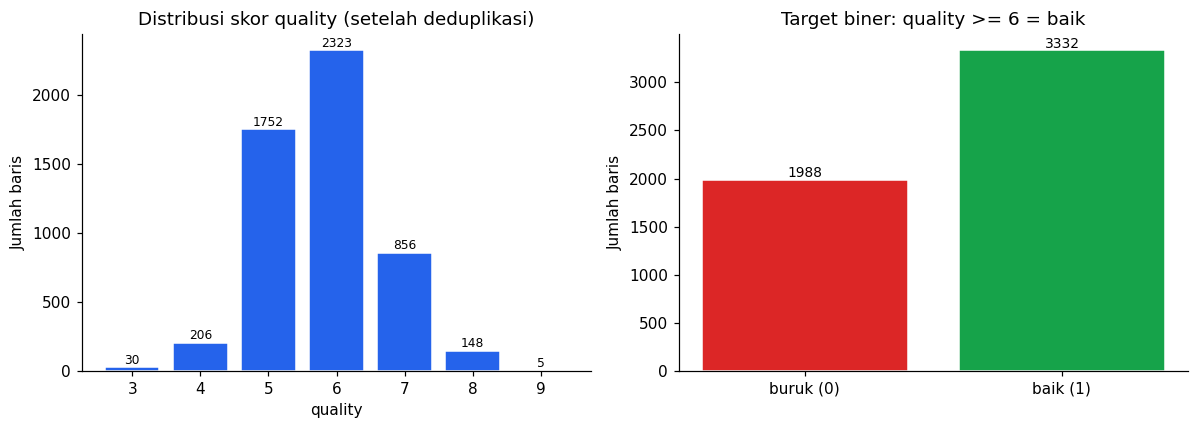

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

quality_counts = wine["quality"].value_counts().sort_index()
axes[0].bar(quality_counts.index.astype(int), quality_counts.values,
            color=COLORS["blue"], edgecolor="white")
axes[0].set_title("Distribusi skor quality (setelah deduplikasi)")
axes[0].set_xlabel("quality")
axes[0].set_ylabel("Jumlah baris")
for x, y in zip(quality_counts.index.astype(int), quality_counts.values):
    axes[0].text(x, y + 25, str(y), ha="center", fontsize=8)

binary_counts = wine["target"].value_counts().sort_index()
bars = axes[1].bar(
    ["buruk (0)", "baik (1)"],
    [binary_counts.get(0, 0), binary_counts.get(1, 0)],
    color=[COLORS["red"], COLORS["green"]],
    edgecolor="white",
)
axes[1].set_title("Target biner: quality >= 6 = baik")
axes[1].set_ylabel("Jumlah baris")
for bar in bars:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, height + 25,
                 f"{int(height)}", ha="center", fontsize=9)

axes[0].grid(False)
axes[1].grid(False)
fig.tight_layout()
plt.show()

## Split dan baseline

Split 80/20 

In [4]:
X_clf = wine[FEATURES]
y_clf = wine["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=TEST_SIZE, stratify=y_clf, random_state=RANDOM_STATE
)
cv_clf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} baris | test: {len(X_test)} baris")

Train: 4256 baris | test: 1064 baris


In [5]:
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy_clf.fit(X_train, y_train)

default_clf = DecisionTreeClassifier(random_state=RANDOM_STATE)
default_clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

## Tuning hyperparameter

GridSearchCV mencoba kombinasi `criterion`, `max_depth`, `min_samples_leaf`, `ccp_alpha`, dan `class_weight`. Skor pemilihan adalah f1 macro karena kelas tidak seimbang. Tabel berikut menampilkan 10 kombinasi teratas beserta skor train dan validasinya.

In [6]:
param_grid_clf = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(2, 13)),
    "min_samples_leaf": [1, 5, 20, 50],
    "ccp_alpha": [0.0, 0.0005, 0.001],
    "class_weight": [None, "balanced"],
}

start_clf = time.time()
grid_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_clf,
    cv=cv_clf,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)
grid_clf.fit(X_train, y_train)
best_clf = grid_clf.best_estimator_

print(f"{len(grid_clf.cv_results_['params'])} kombinasi x {N_FOLDS} fold "
      f"dalam {time.time() - start_clf:.1f} detik")
print({key: grid_clf.best_params_[key] for key in param_grid_clf})
print(f"CV f1_macro = {grid_clf.best_score_:.4f} | "
      f"depth = {best_clf.get_depth()} | leaf = {best_clf.get_n_leaves()}")

528 kombinasi x 5 fold dalam 15.2 detik
{'criterion': 'gini', 'max_depth': 9, 'min_samples_leaf': 1, 'ccp_alpha': 0.001, 'class_weight': None}
CV f1_macro = 0.7217 | depth = 9 | leaf = 35


In [7]:
pd.DataFrame(grid_clf.cv_results_).sort_values("rank_test_score").head(10)[[
    "rank_test_score", "mean_test_score", "std_test_score", "mean_train_score",
    "param_criterion", "param_max_depth", "param_min_samples_leaf",
    "param_ccp_alpha", "param_class_weight",
]].round(4)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_criterion,param_max_depth,param_min_samples_leaf,param_ccp_alpha,param_class_weight
380,1,0.7217,0.0096,0.7879,gini,9,1,0.0010,None
502,2,0.7205,0.0151,0.7553,entropy,6,20,0.0010,balanced
384,3,0.7203,0.0087,0.7903,gini,10,1,0.0010,None
144,4,0.7201,0.0130,0.7477,entropy,5,1,0.0000,balanced
320,4,0.7201,0.0130,0.7477,entropy,5,1,0.0005,balanced
496,6,0.7199,0.0128,0.7476,entropy,5,1,0.0010,balanced
376,7,0.7198,0.0105,0.7850,gini,8,1,0.0010,None
381,8,0.7198,0.0092,0.7864,gini,9,5,0.0010,None
150,9,0.7195,0.0163,0.7561,entropy,6,20,0.0000,balanced
326,9,0.7195,0.0163,0.7561,entropy,6,20,0.0005,balanced


## Evaluasi data test

In [8]:
def evaluate_clf(model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "f1 macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "roc auc": roc_auc_score(y_test, y_proba),
        "pr auc": average_precision_score(y_test, y_proba),
    }


clf_scores = pd.DataFrame({
    "dummy (mayoritas)": evaluate_clf(dummy_clf),
    "tree default": evaluate_clf(default_clf),
    "tree tuned": evaluate_clf(best_clf),
}).T
clf_scores.round(4)

,accuracy,balanced accuracy,precision,recall,f1,f1 macro,roc auc,pr auc
dummy (mayoritas),0.6259,0.5000,0.6259,1.0000,0.7699,0.3850,0.5000,0.6259
tree default,0.6880,0.6648,0.7478,0.7568,0.7522,0.6655,0.6648,0.7181
tree tuned,0.7331,0.7206,0.7966,0.7703,0.7832,0.7180,0.7883,0.8512


In [9]:
cv_acc = cross_val_score(best_clf, X_train, y_train, cv=cv_clf, scoring="accuracy", n_jobs=-1)
cv_f1 = cross_val_score(best_clf, X_train, y_train, cv=cv_clf, scoring="f1_macro", n_jobs=-1)
print(f"CV accuracy : {cv_acc.mean():.4f} +/- {cv_acc.std():.4f}")
print(f"CV f1 macro : {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}")

cm_clf = confusion_matrix(y_test, best_clf.predict(X_test))
display(pd.DataFrame(cm_clf, index=["aktual buruk", "aktual baik"],
                     columns=["prediksi buruk", "prediksi baik"]))

CV accuracy : 0.7408 +/- 0.0084
CV f1 macro : 0.7217 +/- 0.0096


,prediksi buruk,prediksi baik
aktual buruk,267,131
aktual baik,153,513


**Grafik Confusion matrix model terbaik pada data test.**

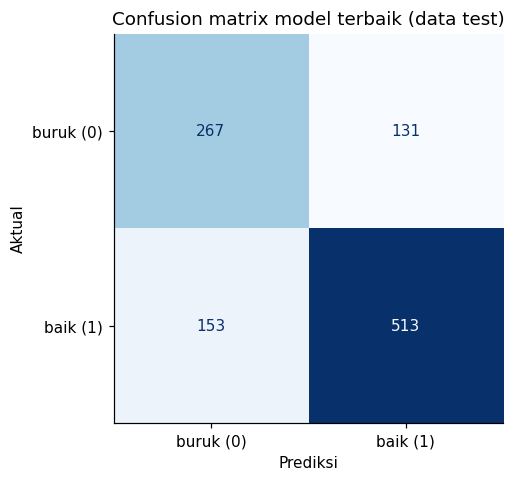

In [10]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
ConfusionMatrixDisplay(confusion_matrix=cm_clf, display_labels=["buruk (0)", "baik (1)"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("Confusion matrix model terbaik (data test)")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.grid(False)
plt.show()

**Grafik Kurva ROC dan kurva Precision-Recall.**

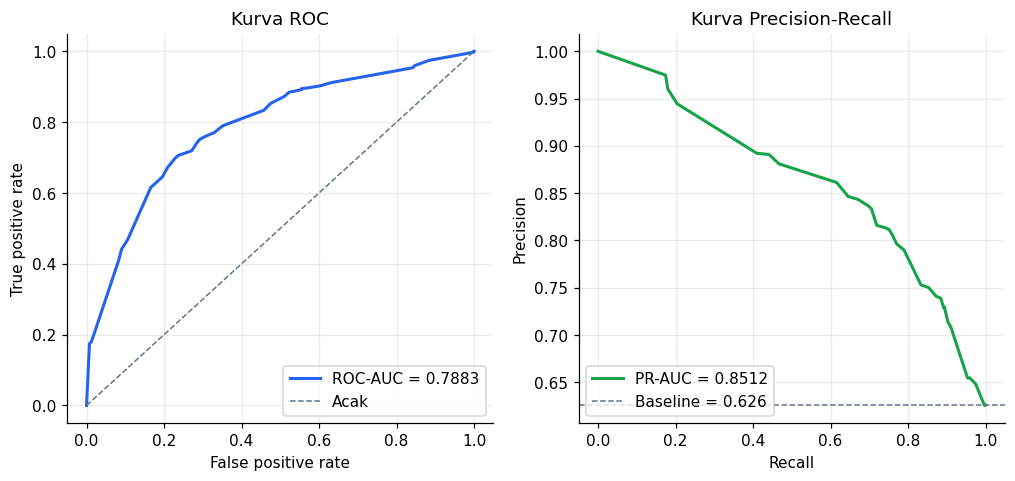

In [11]:
y_proba_clf = best_clf.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba_clf)
precision, recall, _ = precision_recall_curve(y_test, y_proba_clf)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

axes[0].plot(fpr, tpr, color=COLORS["blue"], linewidth=2,
             label=f"ROC-AUC = {roc_auc_score(y_test, y_proba_clf):.4f}")
axes[0].plot([0, 1], [0, 1], "--", color=COLORS["gray"], linewidth=1, label="Acak")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("Kurva ROC")
axes[0].legend(loc="lower right")

baseline = y_test.mean()
axes[1].plot(recall, precision, color=COLORS["green"], linewidth=2,
             label=f"PR-AUC = {average_precision_score(y_test, y_proba_clf):.4f}")
axes[1].axhline(baseline, linestyle="--", color=COLORS["gray"], linewidth=1,
                label=f"Baseline = {baseline:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Kurva Precision-Recall")
axes[1].legend(loc="lower left")

plt.show()

## 5. Analisis kurva dan struktur pohon

**Grafik Akurasi terhadap max_depth.**


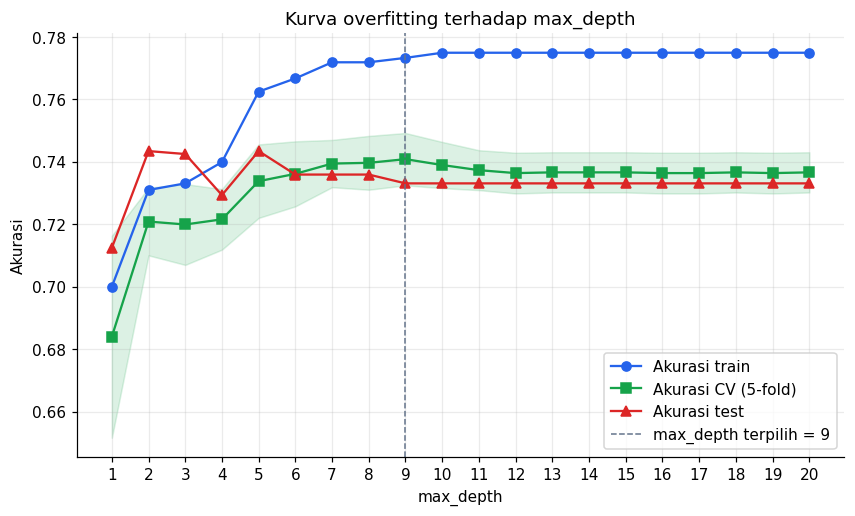

In [12]:
def plot_depth_curve(model, X_train, y_train, X_test, y_test, cv, best_depth):
    depths = list(range(1, 21))
    train_scores, test_scores, cv_scores, cv_stds = [], [], [], []

    for depth in depths:
        fitted = clone(model).set_params(max_depth=depth).fit(X_train, y_train)
        train_scores.append(fitted.score(X_train, y_train))
        test_scores.append(fitted.score(X_test, y_test))
        scores = cross_val_score(
            clone(model).set_params(max_depth=depth),
            X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1,
        )
        cv_scores.append(scores.mean())
        cv_stds.append(scores.std())

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(depths, train_scores, "o-", color=COLORS["blue"], label="Akurasi train")
    ax.plot(depths, cv_scores, "s-", color=COLORS["green"], label="Akurasi CV (5-fold)")
    ax.fill_between(depths,
                    np.array(cv_scores) - np.array(cv_stds),
                    np.array(cv_scores) + np.array(cv_stds),
                    color=COLORS["green"], alpha=0.15)
    ax.plot(depths, test_scores, "^-", color=COLORS["red"], label="Akurasi test")
    ax.axvline(best_depth, color=COLORS["gray"], linestyle="--", linewidth=1,
               label=f"max_depth terpilih = {best_depth}")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("Akurasi")
    ax.set_title("Kurva overfitting terhadap max_depth")
    ax.set_xticks(depths)
    ax.legend(loc="lower right")
    plt.show()


plot_depth_curve(best_clf, X_train, y_train, X_test, y_test, cv_clf, best_clf.get_depth())

**Grafik Feature importance dan permutation importance.**


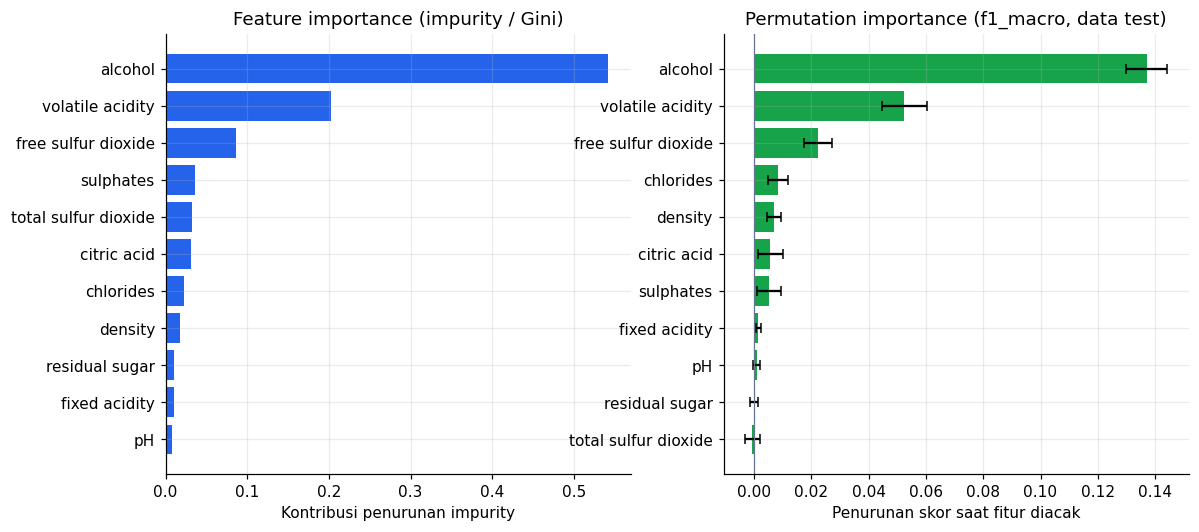

,impurity (gini),permutation (f1_macro),std
alcohol,0.5423,0.1371,0.0072
volatile acidity,0.2029,0.0524,0.0078
free sulfur dioxide,0.0860,0.0225,0.0049
chlorides,0.0231,0.0083,0.0034
density,0.0172,0.0069,0.0024
citric acid,0.0317,0.0057,0.0044
sulphates,0.0359,0.0053,0.0042
fixed acidity,0.0101,0.0015,0.0009
pH,0.0077,0.0010,0.0012
residual sugar,0.0109,-0.0001,0.0013


In [13]:
impurity_clf = pd.Series(best_clf.feature_importances_, index=FEATURES)
perm_clf = permutation_importance(
    best_clf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
    scoring="f1_macro", n_jobs=-1,
)
importance_clf = pd.DataFrame({
    "impurity (gini)": impurity_clf,
    "permutation (f1_macro)": perm_clf.importances_mean,
    "std": perm_clf.importances_std,
}).sort_values("permutation (f1_macro)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
ordered_imp = impurity_clf.sort_values()
axes[0].barh(ordered_imp.index, ordered_imp.values, color=COLORS["blue"])
axes[0].set_title("Feature importance (impurity / Gini)")
axes[0].set_xlabel("Kontribusi penurunan impurity")

ordered_perm = importance_clf.sort_values("permutation (f1_macro)")
axes[1].barh(ordered_perm.index, ordered_perm["permutation (f1_macro)"],
             xerr=ordered_perm["std"], color=COLORS["green"], capsize=3)
axes[1].axvline(0, color=COLORS["gray"], linewidth=0.8)
axes[1].set_title("Permutation importance (f1_macro, data test)")
axes[1].set_xlabel("Penurunan skor saat fitur diacak")
plt.show()

importance_clf.round(4)

**Grafik Learning curve model terbaik.**


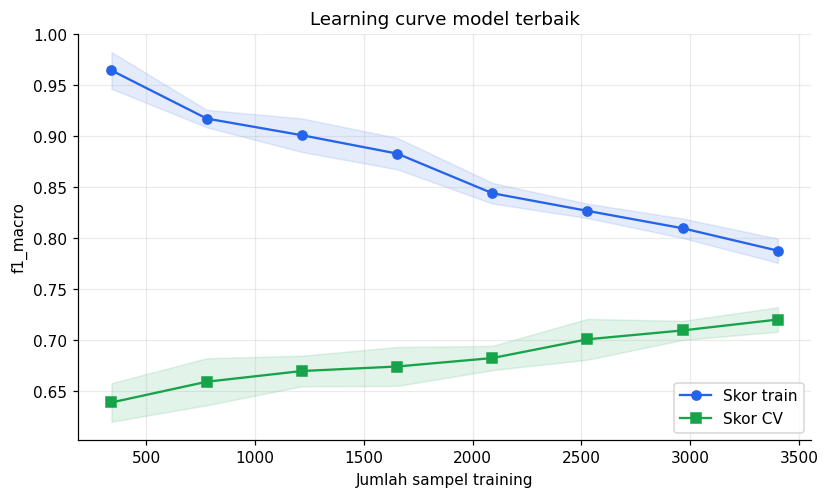

In [14]:
sizes, train_scores, cv_scores = learning_curve(
    best_clf, X_train, y_train, cv=cv_clf, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, random_state=RANDOM_STATE,
)

fig, ax = plt.subplots(figsize=(8.6, 4.8))
for scores, marker, color, label in [
    (train_scores, "o-", COLORS["blue"], "Skor train"),
    (cv_scores, "s-", COLORS["green"], "Skor CV"),
]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, marker, color=color, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.12)
ax.set_xlabel("Jumlah sampel training")
ax.set_ylabel("f1_macro")
ax.set_title("Learning curve model terbaik")
ax.legend(loc="lower right")
plt.show()

**Grafik Struktur pohon keputusan model terbaik.**

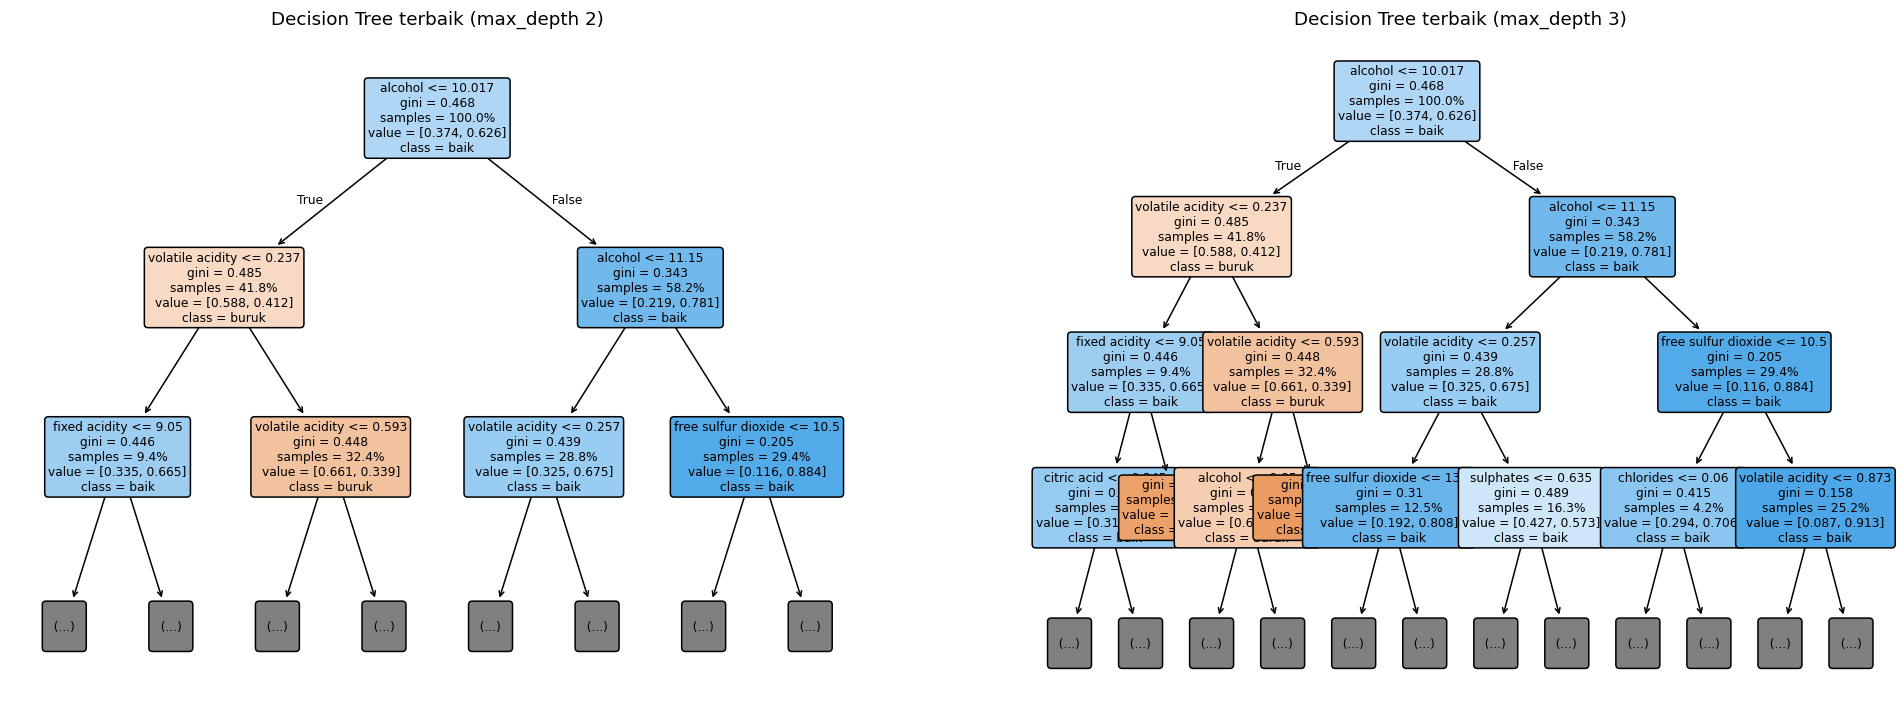

|--- alcohol <= 10.02
|   |--- volatile acidity <= 0.24
|   |   |--- fixed acidity <= 9.05
|   |   |   |--- citric acid <= 0.24
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- citric acid >  0.24
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- fixed acidity >  9.05
|   |   |   |--- class: 0
|   |--- volatile acidity >  0.24
|   |   |--- volatile acidity <= 0.59
|   |   |   |--- alcohol <= 9.85
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- alcohol >  9.85
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- volatile acidity >  0.59
|   |   |   |--- class: 0
|--- alcohol >  10.02
|   |--- alcohol <= 11.15
|   |   |--- volatile acidity <= 0.26
|   |   |   |--- free sulfur dioxide <= 13.50
|   |   |   |   |--- class: 1
|   |   |   |--- free sulfur dioxide >  13.50
|   |   |   |   |--- class: 1
|   |   |--- volatile acidity >  0.26
|   |   |   |--- sulphates <= 0.63
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |---

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, depth in zip(axes, (2, 3)):
    plot_tree(
        best_clf, max_depth=depth, feature_names=FEATURES, class_names=["buruk", "baik"],
        filled=True, rounded=True, proportion=True, impurity=True, fontsize=8, ax=ax,
    )
    ax.set_title(f"Decision Tree terbaik (max_depth {depth})")
plt.show()

print(export_text(best_clf, feature_names=FEATURES, max_depth=3, decimals=2))